In [1]:
import pandas as pd

wind = pd.read_csv("ods031_offshore_2024_2025.csv")
wind.head()

,datetime,measured,dayaheadforecast,monitoredcapacity
0,2024-01-02T11:00:00+01:00,1644.27,2061.3,2262.1
1,2024-01-02T10:30:00+01:00,1532.84,2075.2,2262.1
2,2024-01-02T09:15:00+01:00,2006.62,2084.2,2262.1
3,2024-01-02T09:00:00+01:00,2057.67,2090.3,2262.1
4,2024-01-02T07:15:00+01:00,2080.83,2140.6,2262.1


In [3]:
wind["datetime"] = pd.to_datetime(wind["datetime"], utc=True)  # convert text to real timestamps
wind = wind.sort_values("datetime").reset_index(drop=True)     # rows came in random order, so sort by time
wind["monitoredcapacity"] = wind["monitoredcapacity"].ffill()  # fill the 116 missing values with the previous value

# Forecast error = forecast - actual (positive = forecast was too high)
wind["error_MW"] = wind["dayaheadforecast"] - wind["measured"]
wind["error_pct"] = wind["error_MW"] / wind["monitoredcapacity"] * 100

print("Mean error (bias):", wind["error_MW"].mean().round(1), "MW")
print("Mean absolute error (MAE):", wind["error_MW"].abs().mean().round(1), "MW")
print("MAE as % of installed capacity:", wind["error_pct"].abs().mean().round(2), "%")

Mean error (bias): 20.9 MW
Mean absolute error (MAE): 152.2 MW
MAE as % of installed capacity: 6.73 %


In [4]:
# Each row is 15 minutes = 0.25 hour, so energy (MWh) = power (MW) x 0.25
wind["energy_MWh"] = wind["measured"] * 0.25
wind["abs_error_MWh"] = wind["error_MW"].abs() * 0.25
wind["year"] = wind["datetime"].dt.tz_convert("Europe/Brussels").dt.year

yearly = wind.groupby("year").agg(
    energy_MWh=("energy_MWh", "sum"),
    abs_error_MWh=("abs_error_MWh", "sum"),
    capacity_MW=("monitoredcapacity", "mean"),
    hours=("energy_MWh", "size"),
)
yearly["hours"] = yearly["hours"] * 0.25                       # number of rows -> hours
yearly["capacity_factor_%"] = yearly["energy_MWh"] / (yearly["capacity_MW"] * yearly["hours"]) * 100

# Scale to Rentel (308.7 MW) as the example wind farm
rentel_share = 308.7 / yearly["capacity_MW"]
yearly["rentel_energy_MWh"] = yearly["energy_MWh"] * rentel_share

print(yearly.round(1))

      energy_MWh  abs_error_MWh  capacity_MW   hours  capacity_factor_%  \
year                                                                      
2024   7071028.9      1348141.9       2262.1  8784.0               35.6   
2025   6768843.6      1322219.5       2261.9  8760.0               34.2   

      rentel_energy_MWh  
year                     
2024           964955.8  
2025           923806.4  


In [5]:
# Peek at the first rows of the two imbalance price datasets
base = "https://opendata.elia.be/api/explore/v2.1/catalog/datasets/{}/exports/csv?limit=3&delimiter=;"

for ds in ["ods047", "ods134"]:
    peek = pd.read_csv(base.format(ds), sep=";")
    print(ds)
    print(peek.columns.tolist())
    print(peek.head(3))
    print()

ods047
['datetime', 'qualitystatus', 'resolutioncode', 'netregulationvolume', 'systemimbalance', 'alpha', 'marginalincrementalprice', 'marginaldecrementalprice', 'strategicreserveprice', 'positiveimbalanceprice', 'negativeimbalanceprice']
                    datetime qualitystatus resolutioncode  \
0  2024-05-21T21:45:00+00:00     Validated          PT15M   
1  2024-05-21T21:30:00+00:00     Validated          PT15M   
2  2024-05-21T21:15:00+00:00     Validated          PT15M   

   netregulationvolume  systemimbalance  alpha  marginalincrementalprice  \
0               56.474          -65.454    0.0                     70.00   
1               84.264         -112.370    0.0                     94.89   
2               63.907          -92.096    0.0                    120.88   

   marginaldecrementalprice  strategicreserveprice  positiveimbalanceprice  \
0                     29.76                    NaN                   70.00   
1                     30.00                    NaN     

In [6]:
from urllib.parse import urlencode

def download_elia(dataset, start, end):
    """Download one Elia dataset between two dates as a DataFrame."""
    url = f"https://opendata.elia.be/api/explore/v2.1/catalog/datasets/{dataset}/exports/csv"
    params = {"where": f"datetime >= '{start}' and datetime < '{end}'", "delimiter": ";"}
    return pd.read_csv(url + "?" + urlencode(params), sep=";")

old = download_elia("ods047", "2024-01-01", "2024-05-22")   # old design
new = download_elia("ods134", "2024-05-22", "2026-01-01")   # new design

old.to_csv("ods047_imbalance_2024.csv", index=False)
new.to_csv("ods134_imbalance_2024_2025.csv", index=False)

print("old:", old.shape, "new:", new.shape)
print("resolution codes in new:", new["resolutioncode"].unique())
print("price columns in new:", [c for c in new.columns if "price" in c])

old: (13624, 11) new: (56544, 10)
resolution codes in new: <StringArray>
['PT15M']
Length: 1, dtype: str
price columns in new: ['marginalincrementalprice', 'marginaldecrementalprice', 'imbalanceprice']


In [7]:
# 1. Put old and new prices into one table with the same column name
old["price"] = old["positiveimbalanceprice"]   # single price: positive = negative
new["price"] = new["imbalanceprice"]
prices = pd.concat([old[["datetime", "price"]], new[["datetime", "price"]]])
prices["datetime"] = pd.to_datetime(prices["datetime"], utc=True)
prices = prices.drop_duplicates("datetime")

# 2. Match each wind quarter-hour with its imbalance price
df = wind.merge(prices, on="datetime", how="inner")
print("matched rows:", len(df), "of", len(wind))

# 3. Imbalance = actual - forecast (positive = we produced MORE than sold)
df["imbalance_MWh"] = (df["measured"] - df["dayaheadforecast"]) * 0.25
df["settlement_EUR"] = df["imbalance_MWh"] * df["price"]   # + = received, - = paid

# 4. Average price when we are short vs long
short = df[df["imbalance_MWh"] < 0]
long = df[df["imbalance_MWh"] > 0]
print("avg price when wind is SHORT (we buy):", short["price"].mean().round(1), "EUR/MWh")
print("avg price when wind is LONG (we sell):", long["price"].mean().round(1), "EUR/MWh")

# 5. Yearly summary
summary = df.groupby("year").agg(
    net_imbalance_MWh=("imbalance_MWh", "sum"),
    settlement_EUR=("settlement_EUR", "sum"),
    avg_price=("price", "mean"),
)
summary.round(0)

matched rows: 70164 of 70176
avg price when wind is SHORT (we buy): 87.0 EUR/MWh
avg price when wind is LONG (we sell): 61.7 EUR/MWh


,net_imbalance_MWh,settlement_EUR,avg_price
year,,,
2024,-258107.0,-51360630.0,70.0
2025,-108779.0,-34509874.0,83.0


## Figure 1: Day-ahead forecast vs actual output (one week)

This figure compares the actual offshore wind output (`measured`) with Elia's
day-ahead forecast (`dayaheadforecast`) for one week, at 15-minute resolution.
The shaded area between the two lines is the forecast error.

- Data: Elia Open Data ods031, all Belgian offshore wind farms (~2.26 GW)
- Forecast error = forecast − actual (positive = forecast too high)

**Observation:** _(write what you see: when is the error largest? sudden drops? storms?)_

Matplotlib is building the font cache; this may take a moment.


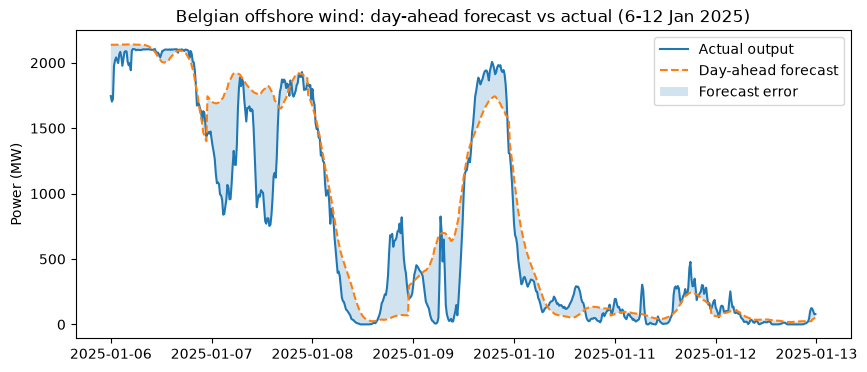

In [8]:
import matplotlib.pyplot as plt

# Pick one week (change the dates to try other weeks)
start = pd.Timestamp("2025-01-06", tz="UTC")
end = pd.Timestamp("2025-01-13", tz="UTC")
week = wind[(wind["datetime"] >= start) & (wind["datetime"] < end)]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(week["datetime"], week["measured"], label="Actual output")
ax.plot(week["datetime"], week["dayaheadforecast"], label="Day-ahead forecast", linestyle="--")
ax.fill_between(week["datetime"], week["measured"], week["dayaheadforecast"],
                alpha=0.2, label="Forecast error")
ax.set_ylabel("Power (MW)")
ax.set_title("Belgian offshore wind: day-ahead forecast vs actual (6-12 Jan 2025)")
ax.legend()
fig.savefig("fig1_forecast_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()

## Figure 2: Monthly imbalance settlement (2024–2025)

When actual output differs from the day-ahead forecast, the difference
(imbalance) is settled with Elia at the imbalance price.
Settlement per quarter-hour = (actual − forecast) × 0.25 h × imbalance price.
Red bars = months where wind farms paid in total; green = received.

- Prices: Elia ods047 (until 21 May 2024) and ods134 (from 22 May 2024, new design)
- Assumption: the wind farms sell exactly Elia's day-ahead forecast the day before
- Note: the net settlement includes the energy value of the net shortfall,
  so it is an upper estimate of the pure "forecast error cost"

**Observation:** _(which months are worst? winter vs summer? 2024 vs 2025?)_

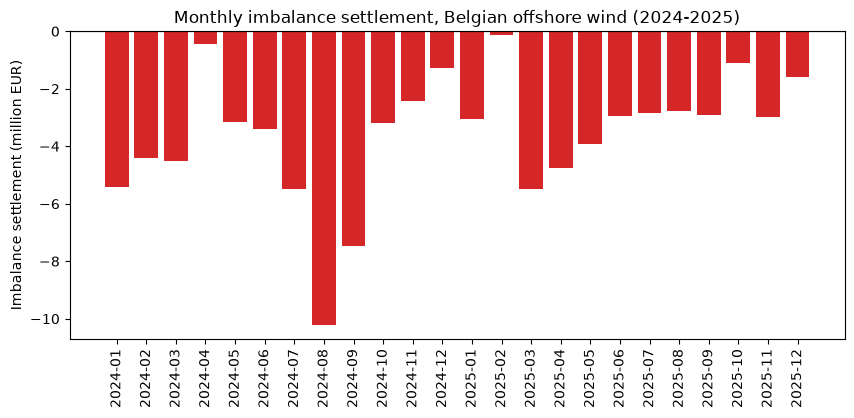

In [9]:
# Sum the settlement per month (in million EUR), using Belgian local time
monthly = (df.set_index(df["datetime"].dt.tz_convert("Europe/Brussels"))["settlement_EUR"]
             .resample("MS").sum() / 1e6)

colors = ["tab:red" if v < 0 else "tab:green" for v in monthly]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly.index.strftime("%Y-%m"), monthly.values, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Imbalance settlement (million EUR)")
ax.set_title("Monthly imbalance settlement, Belgian offshore wind (2024-2025)")
ax.tick_params(axis="x", rotation=90)
fig.savefig("fig2_monthly_settlement.png", dpi=300, bbox_inches="tight")
plt.show()

### Conclusions
1. The day-ahead forecast is fairly accurate but not perfect: the average error
   is about 150 MW, or 6.7% of installed capacity. The bias is small (+21 MW),
   so most errors are random, not a systematic over- or under-forecast.
2. Imbalance prices work against wind. When wind produces less than forecast,
   the system is usually short too, so the price is high (87 €/MWh on average).
   When wind produces more, the system is usually long, so the price is low
   (62 €/MWh). Because Belgian offshore wind is large, its own errors push the
   price in the unfavourable direction.
3. For the whole Belgian offshore fleet the net imbalance settlement was about
   −51 M€ in 2024 and −35 M€ in 2025 (5–7 € per MWh produced). Scaled to
   Rentel this is roughly 5–7 M€ per year, about 2–3.5% of its revenue.
   A more accurate forecast (for example with AI) could reduce this cost,
   which links the data flow (forecast) directly to the money flow.

### Limitations
1. We assume the wind farm sells exactly Elia's day-ahead forecast. Real farms
   may use their own forecasts or trade again in the intraday market.
2. Rentel's numbers are scaled from the whole offshore fleet by capacity
   (308.7 / ~2262 MW), not measured for Rentel itself.
3. The net settlement also includes the value of the energy that was sold but
   not produced, so it overestimates the pure cost of forecast errors.
   A cleaner estimate would compare with the day-ahead market price.
4. Only two years (2024–2025) are analysed, and the imbalance price design
   changed on 22 May 2024.